In [2]:
import pandas as pd
import torch
from torch import nn
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
try:
    df = pd.read_csv("tips.csv")
except FileNotFoundError:
    sns.load_dataset("tips").to_csv("tips.csv", index=False)   # needs internet
    df = pd.read_csv("tips.csv")

In [4]:
df.head()

,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4


In [5]:
print (df.shape)

(244, 7)


In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 244 entries, 0 to 243
Data columns (total 7 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   total_bill  244 non-null    float64
 1   tip         244 non-null    float64
 2   sex         244 non-null    str    
 3   smoker      244 non-null    str    
 4   day         244 non-null    str    
 5   time        244 non-null    str    
 6   size        244 non-null    int64  
dtypes: float64(2), int64(1), str(4)
memory usage: 13.5 KB


In [7]:
df.describe()

,total_bill,tip,size
count,244.000000,244.000000,244.000000
mean,19.785943,2.998279,2.569672
std,8.902412,1.383638,0.951100
min,3.070000,1.000000,1.000000
25%,13.347500,2.000000,2.000000
50%,17.795000,2.900000,2.000000
75%,24.127500,3.562500,3.000000
max,50.810000,10.000000,6.000000


In [8]:
df["size"].isna().sum()
df.isna().sum()

total_bill    0
tip           0
sex           0
smoker        0
day           0
time          0
size          0
dtype: int64

In [ ]:
df["day"].value_counts()        

day
Sat     87
Sun     76
Thur    62
Fri     19
Name: count, dtype: int64

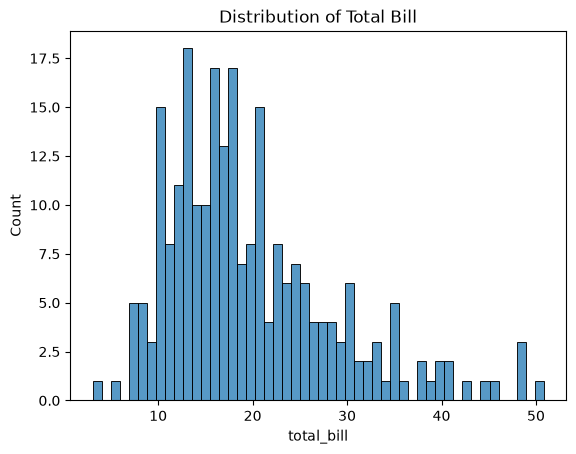

In [16]:
sns.histplot(data=df, x="total_bill", bins=50)
plt.title("Distribution of Total Bill")
plt.show()

<Axes: xlabel='day', ylabel='total_bill'>

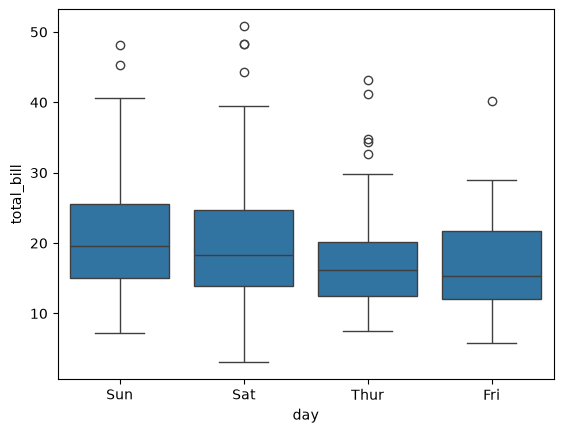

In [23]:
sns.boxplot(data=df, x="day", y="total_bill")

<Axes: xlabel='day', ylabel='tip'>

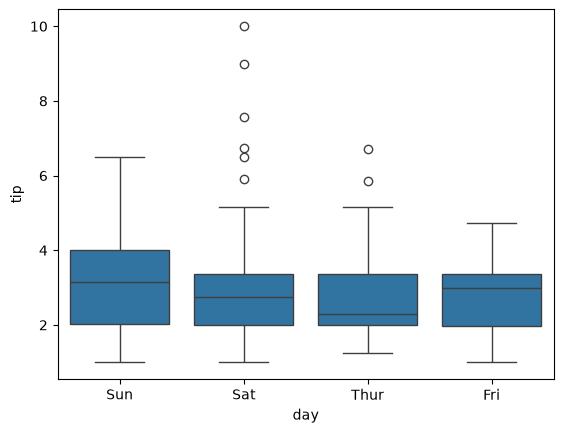

In [24]:
sns.boxplot(data=df, x="day", y="tip")

In [25]:
q1 = df["tip"].quantile(0.25)
q3 = df["tip"].quantile(0.75)    
iqr = q3 - q1

high_fence = q3 + 1.5 * iqr

print (f"Q1: {q1}, Q3: {q3}, IQR: {round (iqr,1)} , High Fence: {round (high_fence,1)}")
print (f"Number of outliers: {df[df['tip'] > high_fence].shape[0]}")
print (f"Outliers: {df[df['tip'] > high_fence]['tip'].values}")



Q1: 2.0, Q3: 3.5625, IQR: 1.6 , High Fence: 5.9
Number of outliers: 9
Outliers: [ 7.58  6.    6.73  6.7  10.    6.5   9.    6.5   5.92]


In [21]:
q1 = df["total_bill"].quantile(0.25)
q3 = df["total_bill"].quantile(0.75)    
iqr = q3 - q1

high_fence = q3 + 1.5 * iqr

print (f"Q1: {q1}, Q3: {q3}, IQR: {round (iqr,1)} , High Fence: {round (high_fence,1)}")
print (f"Number of outliers: {df[df['total_bill'] > high_fence].shape[0]}")
print (f"Outliers: {df[df['total_bill'] > high_fence]['total_bill'].values}")



Q1: 13.3475, Q3: 24.127499999999998, IQR: 10.8 , High Fence: 40.3
Number of outliers: 9
Outliers: [48.27 44.3  41.19 48.17 50.81 45.35 40.55 43.11 48.33]
